# Multi-Class Classification Pipeline: Iris Dataset

## 1. Importing Libraries
This project implements supervised multi-class classification using Logistic Regression and Decision Tree models

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Display settings
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

The Iris dataset contains measurements of three different species of iris flowers.
The objective is to predict the flower species based of four numerical features.

In [2]:
# Load the dataset
df = pd.read_csv("../data/iris.csv")

# Display the first five rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary
df.describe()

Dataset Shape: (150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Count each flower species
print("\nSpecies Distribution:")
print(df["species"].value_counts())

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate Rows: 1

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


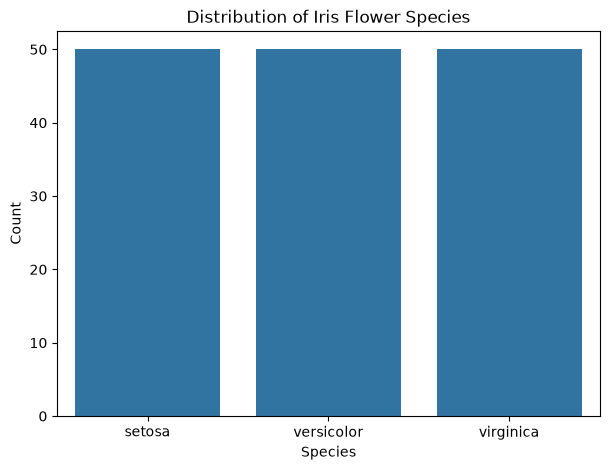

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

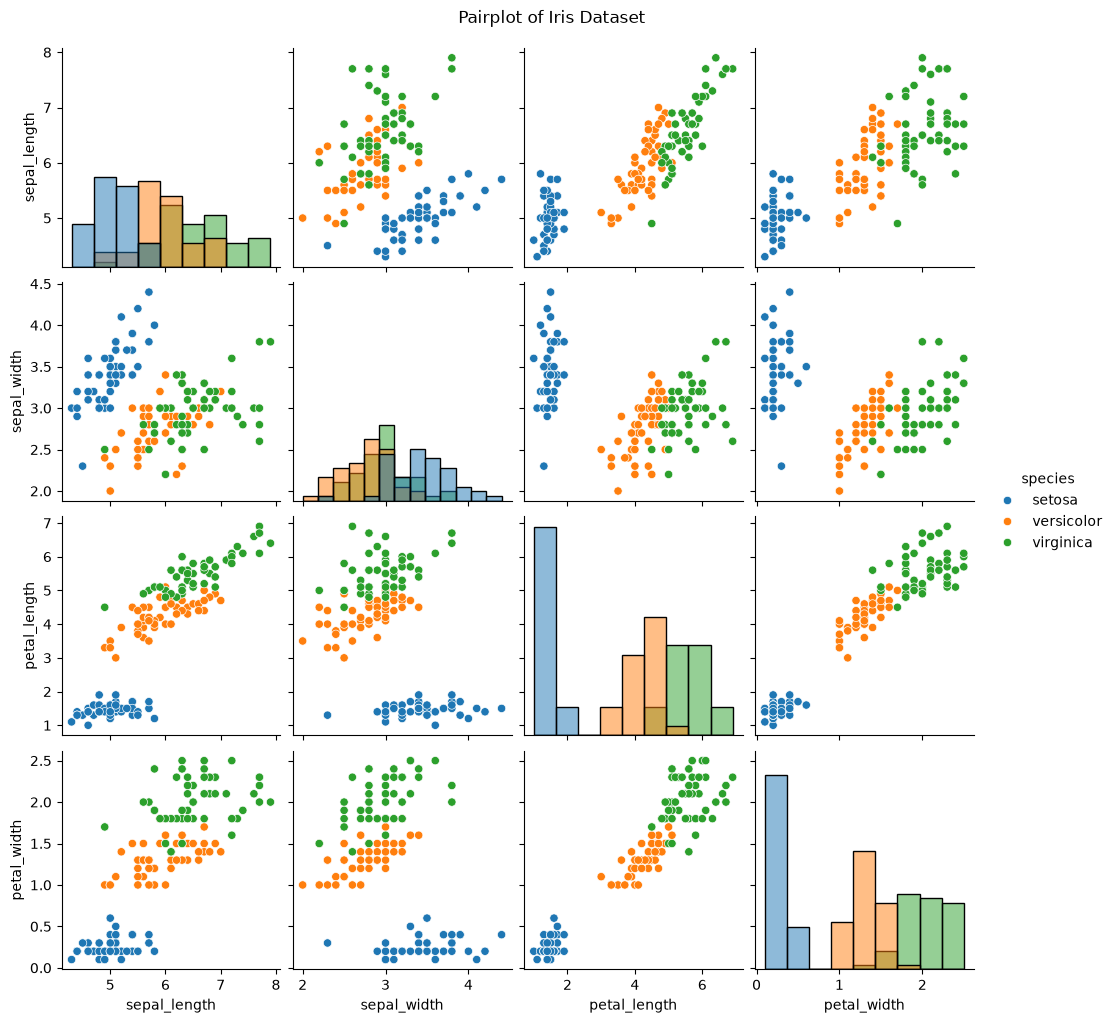

In [6]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Pairplot of Iris Dataset", y=1.02)
plt.show()

## 3. Feature and Target Separation

The four numerical measurements are used as input features (X). The species column is the target variable (y)

In [7]:
# Separate input features and target variable
X = df.drop("species", axis=1)
y = df["species"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (150, 4)
Target Shape: (150,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Features: (120, 4)
Testing Features: (30, 4)


In [9]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

print("\nTraining Data Mean:")
print(X_train_scaled.mean(axis=0))

print("\nTraining Data Standard Deviation:")
print(X_train_scaled.std(axis=0))

Feature scaling completed!

Training Data Mean:
[-1.36927506e-16  9.99200722e-16  1.66533454e-17  1.70234197e-16]

Training Data Standard Deviation:
[1. 1. 1. 1.]


In [10]:
# Initialize Logistic Regression
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [11]:
# Initialize Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
dt_model.fit(X_train_scaled, y_train)

# Make predictions
dt_predictions = dt_model.predict(X_test_scaled)

print("Decision Tree training completed!")

Decision Tree training completed!


## 4. Model Evaluation

Both classification models are evaluated using accuracy, precision, recall, and F1-score.

In [15]:
# Calculate evaluation metrics for Logistic Regression
lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(
    y_test, lr_predictions, average="weighted"
)
lr_recall = recall_score(
    y_test, lr_predictions, average="weighted"
)
lr_f1 = f1_score(
    y_test, lr_predictions, average="weighted"
)

# Calculate evaluation metrics for Decision Tree
dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(
    y_test, dt_predictions, average="weighted"
)
dt_recall = recall_score(
    y_test, dt_predictions, average="weighted"
)
dt_f1 = f1_score(
    y_test, dt_predictions, average="weighted"
)

print("Logistic Regression Classification Report:")
print(classification_report(y_test, lr_predictions))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, dt_predictions))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [16]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [lr_accuracy, dt_accuracy],
    "Precision": [lr_precision, dt_precision],
    "Recall": [lr_recall, dt_recall],
    "F1-Score": [lr_f1, dt_f1]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


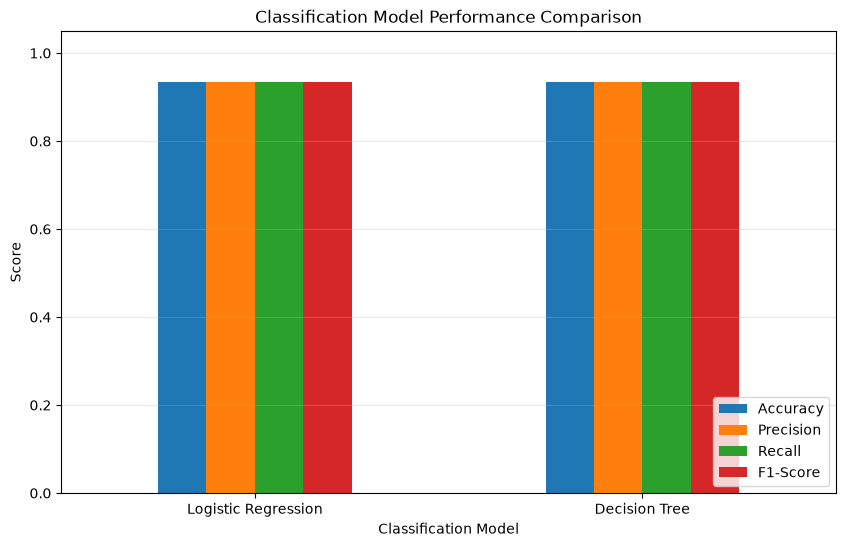

In [17]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.show()

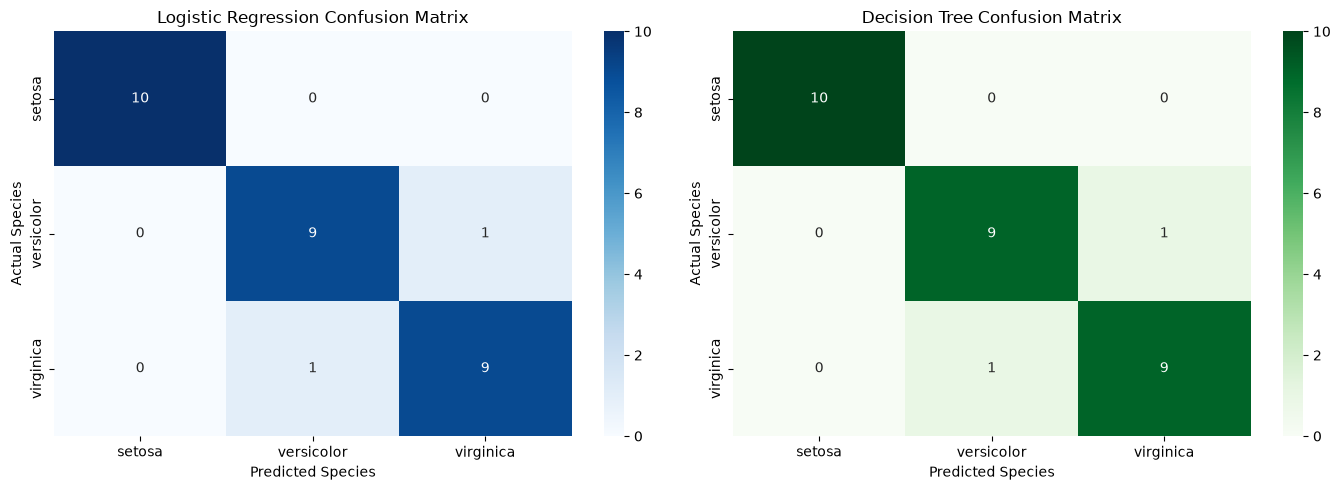

In [18]:
# Define class labels
labels = ["setosa", "versicolor", "virginica"]

# Calculate confusion matrices
lr_cm = confusion_matrix(
    y_test, lr_predictions, labels=labels
)

dt_cm = confusion_matrix(
    y_test, dt_predictions, labels=labels
)

# Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].set_xlabel("Predicted Species")
axes[0].set_ylabel("Actual Species")

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1]
)

axes[1].set_title("Decision Tree Confusion Matrix")
axes[1].set_xlabel("Predicted Species")
axes[1].set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

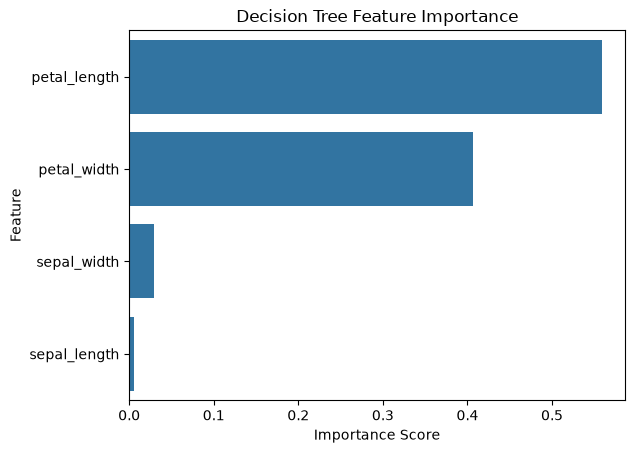

In [19]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()

In [20]:
from sklearn.decomposition import PCA
from sklearn.base import clone
from matplotlib.colors import ListedColormap

In [21]:
def plot_decision_boundary(model, X_train, y_train, title):

    # Scale features and reduce to two dimensions
    scaler_2d = StandardScaler()
    X_scaled = scaler_2d.fit_transform(X_train)

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)

    # Train a separate visualization model
    visual_model = clone(model)
    visual_model.fit(X_pca, y_train)

    # Create mesh grid
    x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
    y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    # Predict regions
    grid_predictions = visual_model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    )

    # Convert class labels to numerical values
    classes = sorted(y_train.unique())
    class_map = {label: i for i, label in enumerate(classes)}

    Z = np.array([
        class_map[label] for label in grid_predictions
    ]).reshape(xx.shape)

    # Plot decision regions
    cmap = ListedColormap(["#FFCCCC", "#CCFFCC", "#CCCCFF"])

    plt.figure(figsize=(9, 6))

    plt.contourf(
        xx, yy, Z,
        alpha=0.4,
        cmap=cmap
    )

    # Plot actual training observations
    y_numeric = y_train.map(class_map)

    plt.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=y_numeric,
        cmap=ListedColormap(["red", "green", "blue"]),
        edgecolor="black"
    )

    plt.title(title)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")

    plt.show()

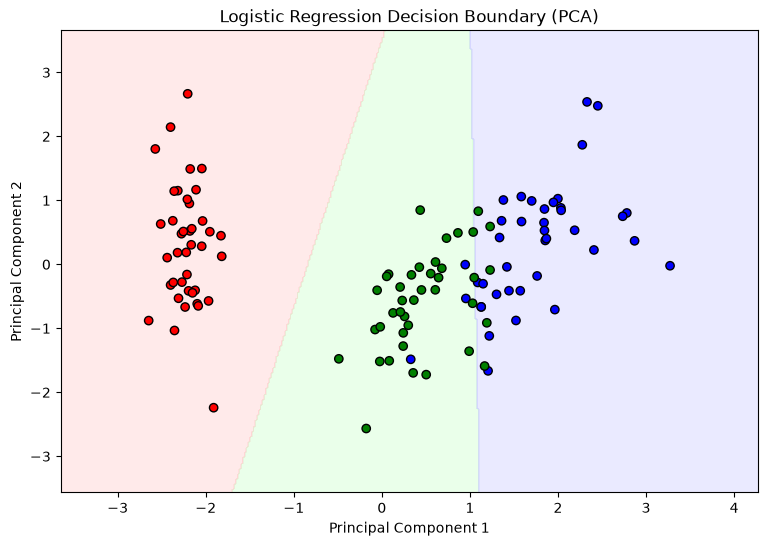

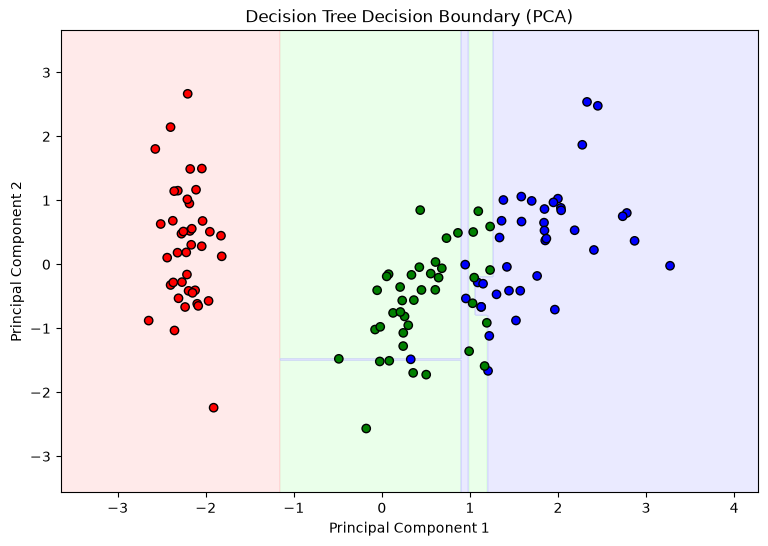

In [22]:
plot_decision_boundary(
    lr_model,
    X_train,
    y_train,
    "Logistic Regression Decision Boundary (PCA)"
)

plot_decision_boundary(
    dt_model,
    X_train,
    y_train,
    "Decision Tree Decision Boundary (PCA)"
)

## 5. Conclusion

In this project, two supervised machine learning algorithms, Logistic Regression and Decision Tree, were implemented using the Iris dataset.

The dataset was explored using Pandas and Seaborn. Feature scaling was performed using StandardScaler, and the dataset was divided into 80% training and 20% testing data.

Both models were evaluated using accuracy, precision, recall, and F1-score.

Confusion matrices were plotted to examine classification performance, while PCA-based decision boundary visualizations
were used to understand how the models separate different classes.

Based on the evaluation results, the model with better overall performance was identified.

This project demonstrates a complete multi-class classification workflow using Scikit-Learn.